# Ten-car opposing queues: smooth forward K-route ORCA-MPPI

This repeats the starts, goals, car geometry, and forward speed limits from
`rrt_connect_warehouse2_car_like_traffic_jam.ipynb` on the same `warehouse2` map.
The corridor planner returns up to `K_ROUTES` radius-aware keep-right paths.
Each car independently samples one returned route uniformly using `ROUTE_SEED`,
and keeps that route throughout the run. ORCA stays enabled for moving cars;
parked cars remain stationary neighbors for the other controllers.

MPPI uses a **6-second prediction horizon** and a forward-facing terminal cost.
The main scenario is forward-only. Jerk is bounded to ±1 unit/s³ and
steering rate to ±0.6 rad/s; acceleration remains an integrated physical state. The separate **simulation duration** is computed
from the longest selected route: twice its travel time at the forward speed limit,
plus 60 seconds for maneuvers and interaction. The default budgets are 212 seconds
for three cars and 282 seconds for ten cars. Simulation stops earlier once every
car is **stopped within 1 map unit of its goal**. Arrival uses jerk-limited braking;
positions, velocities, and acceleration are never reset or teleported.

The pointed end and white windshield show the **front**; the red bar shows the
**rear**. Faint planning lines show alternatives; dashed lines show the sampled
anchors; solid lines show measured trajectories. Run summaries include goal errors,
arrival times, reverse distance, tracking error, and swept clearances.

Build from the project root, then restart the Jupyter kernel:

```bash
cmake -S . -B build/routes -DBUILD_MPPI_CONTROLLER=OFF -DCMAKE_BUILD_TYPE=Release
cmake --build build/routes --target corridor_plan -j2
cmake --build build/release --target mppi_all -j2
```

Install `benchmarks/requirements.txt` in the notebook environment. Run all cells from
the project root or `benchmarks/`. The first planning cell builds and caches the
map graph; `REBUILD_GRAPH = True` regenerates it. Outputs go to
`benchmarks/results/k_routes_warehouse2_car_like_traffic_jam/`. The final cell verifies completion and safety.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle, Polygon as PolygonPatch
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name in {'benchmarks', 'example'}:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'benchmarks'))
sys.path.insert(0, str(ROOT / 'example'))

from bench_mr import boundary_obstacles
from k_routes import prepare_corridor_map, plan_k_routes
from matplotlib.collections import LineCollection
import dyn_models
from params_names import *
import utils

suite = json.loads((ROOT / 'benchmarks/bench_mr_tasks.json').read_text())
world = suite['worlds']['warehouse2']


## Editable opposing queues and car geometry

Each pose is `[x, y, heading]`, with heading in radians. Edit `LEFT_X`, `RIGHT_X`, or `LANE_Y` to move the queues; check that the cars still start outside the inflated obstacles and do not overlap. The body is contained by `ROBOT_RADIUS`, which is passed to the corridor planner and ORCA-MPPI. `WHEELBASE` and `STEER_LIMIT` define the bicycle turn radius.


In [2]:
SEED = 42
PREDICTION_HORIZON_SECONDS = 6.0
SIM_TIME_FACTOR = 2.0
SIM_TIME_MARGIN_SECONDS = 60.0
ROUTE_SEED = 42
K_ROUTES = 5  # Request up to K distinct routes; uniformly sample those returned.
MAX_CANDIDATES = 24
MAX_DETOUR_RATIO = 1.8
DIVERSITY_THRESHOLD = 0.2
REBUILD_GRAPH = False
PLANNER_BINARY = ROOT / 'build/routes/corridor_plan'
GRAPH_PATH = ROOT / 'benchmarks/results/k_routes/input/warehouse2.resources.json'
OUTPUT_DIR = ROOT / 'benchmarks/results/k_routes_warehouse2_car_like_traffic_jam'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LEFT_X = np.array([36.0, 40.0, 44.0, 48.0, 52.0])
RIGHT_X = np.array([100.0, 104.0, 108.0, 112.0, 116.0])
LANE_Y = -41.0
AGENT_NAMES = [f'E{i + 1}' for i in range(len(LEFT_X))] + [f'W{i + 1}' for i in range(len(RIGHT_X))]
CUSTOM_STARTS = np.array(
    [[x, LANE_Y, 0.0] for x in LEFT_X] +
    [[x, LANE_Y, np.pi] for x in RIGHT_X], dtype=float,
)
CUSTOM_GOALS = np.array(
    [[RIGHT_X[i], LANE_Y, 0.0] for i in range(len(LEFT_X))] +
    [[LEFT_X[i], LANE_Y, np.pi] for i in range(len(RIGHT_X))], dtype=float,
)

ROBOT_RADIUS = 0.70
CAR_LENGTH = 1.20
CAR_WIDTH = 0.65
WHEELBASE = 1.00
STEER_LIMIT = 0.60
STEER_RATE_LIMIT = 0.6
MAX_SPEED = 1.2
REVERSE_MAX_SPEED = 0.0  # Forward-only main scenario; enforced through jerk headroom.
ACCEL_MAX = 1.0
BRAKE_MAX = 4.0
PLANNER_CLEARANCE = 0.15
JERK_MIN = -1.0
JERK_MAX = 1.0
DT = 0.1

if len(LEFT_X) != 5 or len(RIGHT_X) != 5:
    raise ValueError('The stress case uses five cars from each side')
if CUSTOM_STARTS.shape != CUSTOM_GOALS.shape or CUSTOM_STARTS.shape != (len(AGENT_NAMES), 3):
    raise ValueError('Provide one [x, y, heading] start and goal per car')
if not np.isfinite(CUSTOM_STARTS).all() or not np.isfinite(CUSTOM_GOALS).all():
    raise ValueError('Start and goal poses must be finite')
if np.hypot(CAR_LENGTH / 2, CAR_WIDTH / 2) > ROBOT_RADIUS:
    raise ValueError('The visible car body must fit inside the collision radius')
if WHEELBASE <= 0 or STEER_LIMIT <= 0 or STEER_LIMIT >= np.pi / 2:
    raise ValueError('Wheelbase and steering limit must define a finite turning radius')
start_distances = np.linalg.norm(
    CUSTOM_STARTS[:, None, :2] - CUSTOM_STARTS[None, :, :2], axis=2,
)
np.fill_diagonal(start_distances, np.inf)
if start_distances.min() <= 2 * ROBOT_RADIUS:
    raise ValueError('Starting car collision envelopes overlap')
print(f'{len(AGENT_NAMES)} cars on warehouse2; minimum initial center spacing '
      f'{start_distances.min():.2f}; bicycle turn radius '
      f'{WHEELBASE / np.tan(STEER_LIMIT):.2f}')


10 cars on warehouse2; minimum initial center spacing 4.00; bicycle turn radius 1.46


## Plan K alternatives and choose one uniformly

The graph is built once from the polygon map and shared across all agents. Every query
uses the car's `ROBOT_RADIUS` and `PLANNER_CLEARANCE`. The native planner validates
all returned paths and applies its keep-right policy without postprocessing.

`K_ROUTES` is an upper bound: diversity, clearance, and bounded search can return fewer.
Each available route has probability `1 / number_of_returned_routes`, regardless of
length or score. An empty set raises an error before simulation. Increase
`MAX_CANDIDATES` to explore more candidates. The saved native JSON includes each
alternative, segment modes, resource traversals, metrics, and validation diagnostics.

Faint lines show all candidate routes over the corridor graph; the bold dashed line
is the sampled anchor passed to MPPI. Starting cars show initial headings.


In [3]:
# The graph is independent of robot radius and reused by both notebooks.
traffic_map = prepare_corridor_map(world, GRAPH_PATH, rebuild=REBUILD_GRAPH)
print(f"Routing graph: {len(traffic_map['routing_geometry']['nodes'])} nodes, "
      f"{len(traffic_map['routing_geometry']['edges'])} edges")
queries = [
    dict(name=name, start=start[:2].tolist(), goal=goal[:2].tolist(),
         radius=ROBOT_RADIUS, safety_margin=PLANNER_CLEARANCE, k=K_ROUTES)
    for name, start, goal in zip(AGENT_NAMES, CUSTOM_STARTS, CUSTOM_GOALS)
]
route_report = plan_k_routes(
    PLANNER_BINARY, GRAPH_PATH, queries, OUTPUT_DIR,
    max_candidates=MAX_CANDIDATES, max_detour_ratio=MAX_DETOUR_RATIO,
    diversity_threshold=DIVERSITY_THRESHOLD,
)
candidate_routes = [query['routes'] for query in route_report['queries']]

# One independent uniform draw per agent, made once before the simulation.
# This generator is separate from the native MPPI seed.
route_rng = np.random.default_rng(ROUTE_SEED)
selected_route_indices = [int(route_rng.integers(len(routes))) for routes in candidate_routes]
selected_routes = [routes[index] for routes, index in zip(candidate_routes, selected_route_indices)]
# Preserve the native keep-right geometry exactly: no shortcut smoothing.
anchor_paths = [route['path'] for route in selected_routes]
route_choices = []
for agent_id, (routes, index, route, query) in enumerate(zip(
        candidate_routes, selected_route_indices, selected_routes, route_report['queries'])):
    choice = dict(agent=AGENT_NAMES[agent_id], requested_k=K_ROUTES,
                  available_routes=len(routes), selected_index=index, route_id=route['id'],
                  probability=1 / len(routes), length=route['metrics']['length'])
    route_choices.append(choice)
    print(f"{choice['agent']}: {len(routes)}/{K_ROUTES} routes; "
          f"selected index {index} (route {route['id']}), p={choice['probability']:.3f}; "
          f"length={choice['length']:.1f}; planning={query['planning_seconds']:.3f}s")
(OUTPUT_DIR / 'route_choices.json').write_text(json.dumps(
    dict(route_seed=ROUTE_SEED, mppi_seed=SEED, radius=ROBOT_RADIUS,
         safety_margin=PLANNER_CLEARANCE, choices=route_choices), indent=2) + '\n')


Routing graph: 173 nodes, 248 edges
E1: 2/5 routes; selected index 0 (route 0), p=0.500; length=72.3; planning=0.037s
E2: 4/5 routes; selected index 3 (route 3), p=0.250; length=132.8; planning=0.107s
E3: 4/5 routes; selected index 2 (route 2), p=0.250; length=124.1; planning=0.107s
E4: 5/5 routes; selected index 2 (route 2), p=0.200; length=116.5; planning=0.139s
E5: 4/5 routes; selected index 1 (route 1), p=0.250; length=107.7; planning=0.103s
W1: 2/5 routes; selected index 1 (route 1), p=0.500; length=84.7; planning=0.036s
W2: 4/5 routes; selected index 0 (route 0), p=0.250; length=72.2; planning=0.105s
W3: 4/5 routes; selected index 2 (route 2), p=0.250; length=112.2; planning=0.111s
W4: 5/5 routes; selected index 1 (route 1), p=0.200; length=125.0; planning=0.136s
W5: 4/5 routes; selected index 0 (route 0), p=0.250; length=69.6; planning=0.105s


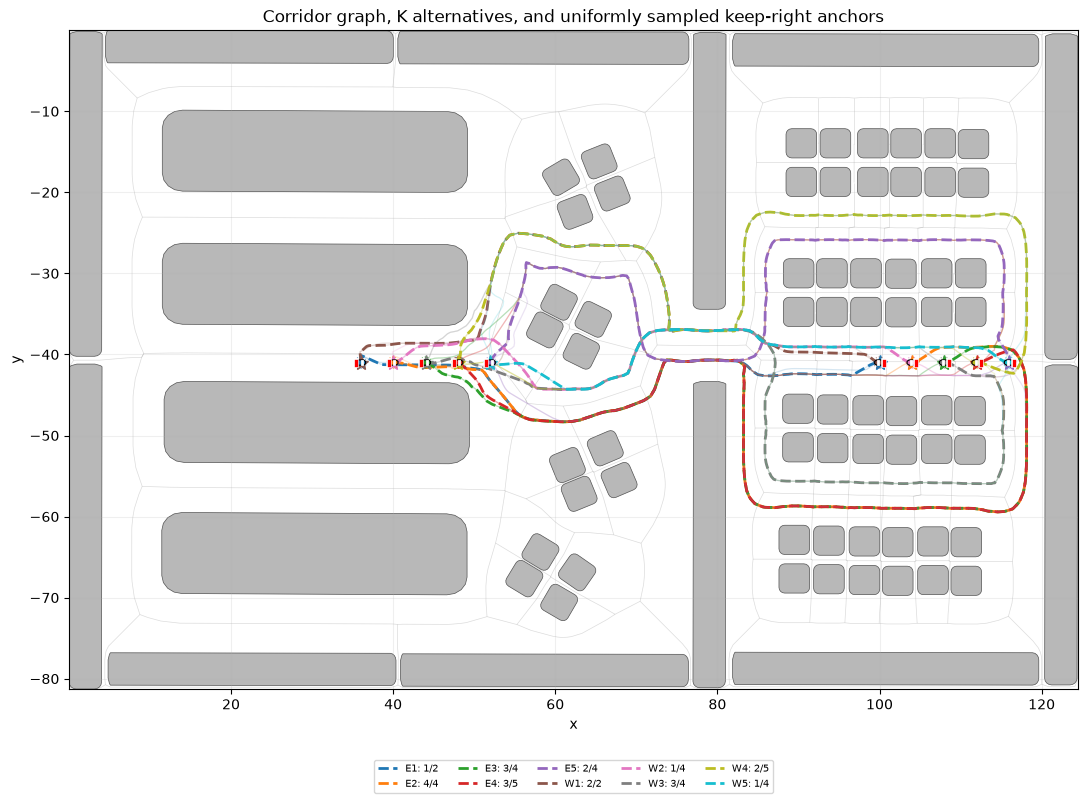

In [4]:
colors = plt.colormaps['tab10'](np.arange(len(AGENT_NAMES)))

def draw_world(ax):
    for vertices in world['obstacles']:
        ax.add_patch(PolygonPatch(vertices, closed=True, facecolor='0.72',
                                  edgecolor='0.32', linewidth=0.5))
    bounds = world['bounds']
    ax.set(xlim=(bounds[0], bounds[2]), ylim=(bounds[1], bounds[3]),
           aspect='equal', xlabel='x', ylabel='y')
    ax.grid(alpha=0.2)

def draw_car(ax, pose, color, alpha=1.0, safety_circle=False):
    """Draw a pointed front, pale windshield, and red rear at the car heading."""
    x, y, heading = pose[:3]
    rotation = np.array([[np.cos(heading), -np.sin(heading)],
                         [np.sin(heading),  np.cos(heading)]])
    def world_points(local):
        return np.asarray(local) @ rotation.T + [x, y]
    half_l, half_w = CAR_LENGTH / 2, CAR_WIDTH / 2
    body = world_points([[-half_l, -half_w], [0.30 * CAR_LENGTH, -half_w],
                         [half_l, -0.45 * half_w], [half_l, 0.45 * half_w],
                         [0.30 * CAR_LENGTH, half_w], [-half_l, half_w]])
    ax.add_patch(PolygonPatch(body, closed=True, facecolor=color,
                              edgecolor='black', linewidth=0.8, alpha=alpha, zorder=5))
    windshield = world_points([[0.12 * CAR_LENGTH, -0.65 * half_w],
                               [0.12 * CAR_LENGTH,  0.65 * half_w]])
    rear = world_points([[-0.88 * half_l, -0.75 * half_w],
                         [-0.88 * half_l,  0.75 * half_w]])
    ax.plot(windshield[:, 0], windshield[:, 1], color='white', linewidth=2.0,
            alpha=alpha, zorder=6)
    ax.plot(rear[:, 0], rear[:, 1], color='white', linewidth=4.0,
            alpha=alpha, zorder=6)
    ax.plot(rear[:, 0], rear[:, 1], color='red', linewidth=2.4,
            alpha=alpha, zorder=7)
    if safety_circle:
        ax.add_patch(Circle((x, y), ROBOT_RADIUS, fill=False, color=color,
                            linestyle=':', linewidth=0.8, alpha=0.65, zorder=4))

fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
ax.add_collection(LineCollection(
    [edge['geometry'] for edge in traffic_map['routing_geometry']['edges']],
    colors='0.55', linewidths=0.5, alpha=0.3, zorder=1,
))
for agent_id, (start, goal, routes, anchor_path) in enumerate(zip(
        CUSTOM_STARTS, CUSTOM_GOALS, candidate_routes, anchor_paths)):
    color = colors[agent_id]
    for route in routes:
        candidate = np.asarray(route['path'])
        ax.plot(*candidate.T, color=color, alpha=0.18, linewidth=0.9)
    anchor = np.asarray(anchor_path)
    index = selected_route_indices[agent_id]
    ax.plot(*anchor.T, '--', color=color, linewidth=2,
            label=f'{AGENT_NAMES[agent_id]}: {index + 1}/{len(routes)}')
    draw_car(ax, start, color, safety_circle=True)
    ax.plot(*goal[:2], '*', color=color, markersize=11)
ax.set_title('Corridor graph, K alternatives, and uniformly sampled keep-right anchors')
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=5)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'planned_routes.png', dpi=160, bbox_inches='tight')
plt.show()


## Concurrent car-like ORCA-MPPI execution and goal parking

State is `[x, y, heading, velocity, steering angle, acceleration]`; controls are
`[jerk, steering_rate]`. The six-state bicycle dynamics are identical in native
prediction and Python execution. Every raw pose increment, velocity increment,
and control derivative is checked below. No trajectories or controls are filtered.

The main tasks use forward speed only, jerk bounds **±1 unit/s³**, and steering-rate
bounds **±0.6 rad/s**. These tighten the earlier limits of ±2 and ±2, respectively.
Speed, acceleration, braking, steering angle, wheelbase, and body geometry retain
the source values. Speed bounds are enforced by jerk feasibility, including the
acceleration headroom needed to approach zero speed continuously.

MPPI samples 256 trajectories over **6 seconds**. Gaussian control perturbations
have variances `[0.25, 0.0225]` and temporal correlation `0.92`, allowing sustained
turns with smaller noise. The control cost uses the matching temporal precision.
ORCA conditions the first jerk distribution and carries that change into the
correlated future samples. The proximity cost tends continuously to zero at its
cutoff, removing its old artificial cost step. Hard collision checks and ORCA
settings remain enabled.

A quarter of the rollout batch uses bounded tracking/offset proposals, with
several preview distances and speeds. Lateral offsets support entry turns and
avoid stationary or crossing traffic. Neighbors already travelling along the
same route are followed, keeping strong lane tracking instead of overtaking.
The rest uses correlated Gaussian exploration. Every candidate is propagated
and scored inside MPPI; ORCA still conditions every first jerk. These proposals
never replace the selected route or bypass the controller. If averaging safe
left/right modes would collide, MPPI keeps the best feasible mode.

The lateral weight is `3000`. `ANCHOR_ACQUISITION_SCALE = 0.02` eases lateral
and heading costs while the measured car is misaligned or approaching a neighbor.
This allows physical entry and passing turns; strong lane tracking returns in
clear space. All candidates share this measured-state scale. Effort weights are
`1000/2000` and command-change weights `4000/10000` for jerk/steering rate,
including the last executed command.

If simultaneous updates produce a small overlap of extra clearance margins,
only monotone separation can recover it. Physical body overlap stays forbidden.
This allows an already separated car to move away instead of rejecting every
candidate because of its shared initial state. The state equations and physical
control bounds remain intact throughout recovery.

Prediction and simulation duration are separate. The run budget is
`SIM_TIME_FACTOR * longest_route / MAX_SPEED + SIM_TIME_MARGIN_SECONDS`.
Cars brake physically when their remaining stopping arc fits inside the 1-unit
goal disk, then stay parked and remain ORCA neighbors. Success requires all cars
inside that disk with zero speed and acceleration. The final cell checks this,
physical bounds, collisions, and independent swept clearances.

Near the route end, heading guidance points toward the endpoint and fades with
distance to it. Passing offsets taper to zero. An overshoot therefore asks for
a physical forward turn back toward the finish, rather than rewarding travel
along the old final tangent.


In [5]:
AGENTS_NUM = len(AGENT_NAMES)
start_states = np.c_[CUSTOM_STARTS, np.zeros((AGENTS_NUM, 3))]
goal_states = np.c_[CUSTOM_GOALS, np.zeros((AGENTS_NUM, 3))]

agent_params = {
    AGENT_SIZE: ROBOT_RADIUS, VISIBILITY_RADIUS: 30.0,
    DIFF_DRIVE_V_MAX: MAX_SPEED, DIFF_DRIVE_V_MIN: -REVERSE_MAX_SPEED,
    LONGITUDINAL_ACCEL_MIN: -BRAKE_MAX, LONGITUDINAL_ACCEL_MAX: ACCEL_MAX,
    LONGITUDINAL_JERK_MIN: JERK_MIN, LONGITUDINAL_JERK_MAX: JERK_MAX,
    DIFF_DRIVE_W_MAX: STEER_LIMIT, DIFF_DRIVE_W_MIN: -STEER_LIMIT,
    STEERING_RATE_MAX: STEER_RATE_LIMIT,
}
agents_params = [agent_params.copy() for _ in range(AGENTS_NUM)]
agent_models = [dyn_models.CarLikeDyn(WHEELBASE) for _ in range(AGENTS_NUM)]
alg_params = {
    SAMPLE_BATCH_SIZE: 256, SAMPLE_TIME_STEPS: int(round(PREDICTION_HORIZON_SECONDS / DT)) + 1, TIME_STEP: DT,
    INIT_VALUE: np.zeros(2), CONTROL_MEAN: np.zeros(2),
    # Stationary variances of temporally coherent [jerk, steering_rate] noise.
    CONTROL_COV: np.diag([0.25, 0.0225]),
    ANCHOR_GUIDED_FRACTION: 0.25, CONTROL_NOISE_CORRELATION: 0.92, ANCHOR_ACQUISITION_SCALE: 0.02,
    JERK_COST_WEIGHT: 1000.0, STEERING_RATE_COST_WEIGHT: 2000.0,
    JERK_CHANGE_COST_WEIGHT: 4000.0, STEERING_RATE_CHANGE_COST_WEIGHT: 10000.0,
    RUNNING_COST_WEIGH: 300.0, TERMINAL_WEIGHT: 2000.0,
    SOFTMAX_TEMPERATURE: 0.25, MA_COST_EN: True,
    MA_DIST_WEIGHT: 1200.0, MA_COLLISION_WEIGHT: 1e7,
    MA_DIST_THREASHOLD: 4.0, USE_CAR_LIKE_DYN: True,
    DIST_BETWEEN_AXLES: WHEELBASE,
    K_ALPHA: -2.96, RAD_EPS: 0.15, VELOCITY_COST_WEIGHT: 0.5,
    TERMINAL_LOOKAHEAD_DISTANCE: 6.0, MA_EN_CLOSE_TO_GOAL_DIST: 1.0,
    MA_EN_CLOSE_TO_GOAL_TS: 3, ORCA_TIME_BOUNDARY: 5.0,
    ORCA_RESPONSIBILITY_FACTOR: 1.0, MA_EXCLUDE_COLLISION_TRAJ: True,
    VELOCITY_COST_CLOSE_TO_GOAL_DIST: 0.7, ANCHOR_PATH_WEIGHT: 3000.0,
    ANCHOR_HEADING_WEIGHT: 1000.0, CONTROL_SMOOTHNESS_WEIGHT: 20.0,
    ANCHOR_FORWARD_WEIGHT: 80000.0, REVERSE_COST_WEIGHT: 1000.0,
}
SIMULATION_SECONDS = int(np.ceil(SIM_TIME_FACTOR * max(route["metrics"]["length"] for route in selected_routes) / MAX_SPEED + SIM_TIME_MARGIN_SECONDS))
exp_params = {EXP_TIME_STEP: DT, XY_GOAL_TOLERANCE: 1.0, MAX_EXP_STEPS: int(np.ceil(SIMULATION_SECONDS / DT))}
print(f"Prediction: {PREDICTION_HORIZON_SECONDS:.1f}s; simulation budget: {SIMULATION_SECONDS}s")

expanded_bounds = np.asarray(world['bounds']) + np.array([-1, -1, 1, 1]) * (ROBOT_RADIUS + 0.05)
controller_obstacles = world['obstacles'] + boundary_obstacles(expanded_bounds)
success, collisions, steps, duration, log_state = utils.launch_mppi(
    start_states, goal_states, AGENTS_NUM, agents_params, alg_params, exp_params,
    agent_models, seed=SEED, obstacles=controller_obstacles, anchor_paths=anchor_paths, park_at_goal=True,
)
states = np.asarray(log_state)
xy = states[:, :, :2]
goal_errors = np.linalg.norm(xy[-1] - goal_states[:, :2], axis=1)
unfinished = goal_errors > exp_params[XY_GOAL_TOLERANCE]

# Count cars in the central passage and cars nearly stopped there.
CHOKE_BOUNDS = (60.0, -46.0, 85.0, -37.0)
xmin, ymin, xmax, ymax = CHOKE_BOUNDS
in_choke = ((xy[:, :, 0] >= xmin) & (xy[:, :, 0] <= xmax) &
            (xy[:, :, 1] >= ymin) & (xy[:, :, 1] <= ymax))
choke_counts = in_choke.sum(axis=1)
# Velocity and steering are physical state, not commanded pose increments.
speeds = states[1:, :, 3]
previous_speeds = states[:-1, :, 3]
accelerations = states[:, :, 5]
speed_rates = np.diff(states[:, :, 3], axis=0) / DT
np.testing.assert_allclose(speed_rates, accelerations[:-1], atol=1e-8)
steering_rates = np.diff(states[:, :, 4], axis=0) / DT
jerks = np.diff(accelerations, axis=0) / DT
# Independently verify bicycle pose propagation as well as acceleration.
expected_xy = speeds[..., None] * np.stack(
    [np.cos(states[:-1, :, 2]), np.sin(states[:-1, :, 2])], axis=-1) * DT
np.testing.assert_allclose(np.diff(xy, axis=0), expected_xy, atol=1e-8)
np.testing.assert_allclose(np.diff(states[:, :, 2], axis=0),
                           speeds / WHEELBASE * np.tan(states[1:, :, 4]) * DT, atol=1e-8)
# Raw differences measure chatter; they are diagnostics, not extra controls.
control_values = np.stack([jerks, steering_rates], axis=-1)
control_rms = np.sqrt(np.mean(control_values**2, axis=(0, 1)))
control_change_rms = np.sqrt(np.mean(np.diff(control_values, axis=0)**2, axis=(0, 1)))
print('RMS [jerk, steering_rate]:', np.round(control_rms, 4))
print('RMS successive-command changes:', np.round(control_change_rms, 4))
print(f'jerk near hard bounds: {np.mean((jerks <= 0.95 * JERK_MIN) | (jerks >= 0.95 * JERK_MAX)):.1%}')
max_acceleration = float(accelerations.max())
max_braking = float(-accelerations.min())
assert np.max(states[:, :, 3]) <= MAX_SPEED + 1e-6
assert np.min(states[:, :, 3]) >= -REVERSE_MAX_SPEED - 1e-6
assert accelerations.max() <= ACCEL_MAX + 1e-6
assert accelerations.min() >= -BRAKE_MAX - 1e-6
assert jerks.min() >= JERK_MIN - 1e-6
assert jerks.max() <= JERK_MAX + 1e-6
assert np.max(np.abs(states[:, :, 4])) <= STEER_LIMIT + 1e-6
assert np.max(np.abs(steering_rates)) <= STEER_RATE_LIMIT + 1e-6

reverse_steps = np.sum(speeds < -0.05, axis=0)
forward_after_reverse = []
for agent_id, name in enumerate(AGENT_NAMES):
    reverse_indices = np.flatnonzero(speeds[:, agent_id] < -0.05)
    if len(reverse_indices) and np.any(speeds[reverse_indices[-1] + 1:, agent_id] > 0.05):
        forward_after_reverse.append(name)
SLOW_SPEED = 0.2
slow_in_choke = np.r_[0, ((np.abs(speeds) < SLOW_SPEED) & in_choke[1:]).sum(axis=1)]
lookback = min(30, len(states) - 1)
recent_motion = np.linalg.norm(xy[-1] - xy[-1 - lookback], axis=1)
stalled = unfinished & (recent_motion < 0.5)

closest = (np.inf, None, None, None)
for first in range(AGENTS_NUM):
    for second in range(first + 1, AGENTS_NUM):
        center_distances = np.linalg.norm(xy[:, first] - xy[:, second], axis=1)
        closest_step = int(np.argmin(center_distances))
        gap = float(center_distances[closest_step] - 2 * ROBOT_RADIUS)
        if gap < closest[0]:
            closest = (gap, first, second, closest_step)

print(f'success={success}, collisions={collisions}, steps={steps}, wall time={duration:.2f}s')
print(f'measured a range=[{-max_braking:.2f}, {max_acceleration:.2f}] units/s²; '
      f'max steering rate={np.max(np.abs(steering_rates)):.2f} rad/s')
print(f'measured jerk range=[{jerks.min():.2f}, {jerks.max():.2f}] units/s³; '
      f'max acceleration step={np.max(np.abs(np.diff(accelerations, axis=0))):.3f}')
print(f'reverse steps by car: {dict(zip(AGENT_NAMES, reverse_steps.tolist()))}')
print(f'reversed then moved forward: {forward_after_reverse}')
print(f'cars in bottleneck: peak={choke_counts.max()}/{AGENTS_NUM}, final={choke_counts[-1]}/{AGENTS_NUM}')
print(f'peak nearly stopped in bottleneck (<{SLOW_SPEED} units/s): {slow_in_choke.max()}')
print(f'closest circular-envelope gap: {closest[0]:.3f} '
      f'({AGENT_NAMES[closest[1]]}/{AGENT_NAMES[closest[2]]}, step {closest[3]})')
print(f'unfinished cars: {[AGENT_NAMES[i] for i in np.flatnonzero(unfinished)]}')
print(f'stalled unfinished cars (less than 0.5 units in the last 3 s): '
      f'{[AGENT_NAMES[i] for i in np.flatnonzero(stalled)]}')
for name, error in zip(AGENT_NAMES, goal_errors):
    print(f'{name}: final XY error={error:.2f}')

run_summary = dict(success=bool(success), collisions=int(collisions), steps=int(steps),
                   wall_seconds=float(duration), route_seed=ROUTE_SEED, mppi_seed=SEED,
                   final_goal_errors=dict(zip(AGENT_NAMES, goal_errors.tolist())),
                   unfinished=[name for name, error in zip(AGENT_NAMES, goal_errors)
                               if error > exp_params[XY_GOAL_TOLERANCE]],
                   closest_envelope_gap=float(closest[0]))
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2) + '\n')
np.savez_compressed(OUTPUT_DIR / 'trajectories.npz', states=states, dt=DT)

# Tracking diagnostics separate route acquisition/progress from the time budget.
from shapely.geometry import LineString, Point
tracking_metrics = []
for agent_id, path in enumerate(anchor_paths):
    reference = LineString(path)
    distances = np.array([reference.distance(Point(point)) for point in xy[:, agent_id]])
    progress = reference.project(Point(xy[-1, agent_id]))
    metrics = dict(agent=AGENT_NAMES[agent_id], route_length=reference.length,
                   final_progress=progress, progress_fraction=progress / reference.length,
                   rms_route_distance=float(np.sqrt(np.mean(distances**2))),
                   max_route_distance=float(distances.max()))
    tracking_metrics.append(metrics)
    print(f"{metrics['agent']}: route progress {progress:.1f}/{reference.length:.1f}; "
          f"RMS route distance {metrics['rms_route_distance']:.2f}")
run_summary['tracking'] = tracking_metrics
run_summary['orca_enabled'] = bool(alg_params[MA_COST_EN])
# Exclude parked tails so smoothness cannot improve just by waiting longer.
active = (np.abs(previous_speeds) > 0.05) | (np.abs(accelerations[:-1]) > 0.05)
changes = np.diff(control_values, axis=0)
run_summary['smoothness'] = dict(
    active_control_rms=np.sqrt(np.mean(control_values[active]**2, axis=0)).tolist(),
    active_command_change_rms=np.sqrt(np.mean(changes[(active[1:] | active[:-1])]**2, axis=0)).tolist(),
    peak_absolute_jerk=float(np.max(np.abs(jerks))),
    peak_absolute_steering_rate=float(np.max(np.abs(steering_rates))),
    jerk_limits=[JERK_MIN, JERK_MAX], steering_rate_limit=STEER_RATE_LIMIT,
    control_noise_correlation=alg_params[CONTROL_NOISE_CORRELATION],
    anchor_guided_fraction=alg_params[ANCHOR_GUIDED_FRACTION],
    anchor_acquisition_scale=alg_params[ANCHOR_ACQUISITION_SCALE],
)
route_distances = np.stack([
    np.array([LineString(path).distance(Point(point)) for point in xy[1:, agent_id]])
    for agent_id, path in enumerate(anchor_paths)], axis=1)
run_summary['active_rms_route_distance'] = float(np.sqrt(np.mean(route_distances[active]**2)))
print('Active control RMS [jerk, steering rate]:', run_summary['smoothness']['active_control_rms'])
print('Active RMS distance to route:', run_summary['active_rms_route_distance'])

(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2) + '\n')

# Completion and direction diagnostics from measured states.
run_summary.update(
    prediction_horizon_seconds=PREDICTION_HORIZON_SECONDS,
    simulation_budget_seconds=SIMULATION_SECONDS,
    goal_tolerance=exp_params[XY_GOAL_TOLERANCE],
    final_speeds=states[-1, :, 3].tolist(),
    final_accelerations=states[-1, :, 5].tolist(),
    reverse_distances=(np.maximum(-states[1:, :, 3], 0).sum(axis=0) * DT).tolist(),
)
arrivals = {}
for agent_id, name in enumerate(AGENT_NAMES):
    arrived = ((np.linalg.norm(xy[:, agent_id] - CUSTOM_GOALS[agent_id, :2], axis=1)
                <= exp_params[XY_GOAL_TOLERANCE]) &
               (np.abs(states[:, agent_id, 3]) <= 1e-8) &
               (np.abs(states[:, agent_id, 5]) <= 1e-8))
    indices = np.flatnonzero(arrived)
    arrivals[name] = float(indices[0] * DT) if len(indices) else None
run_summary['arrival_seconds'] = arrivals

# Independent continuous footprint checks on all measured motion segments.
from shapely.geometry import Polygon as ObstaclePolygon, box
static_geometry = [ObstaclePolygon(vertices) for vertices in world['obstacles']]
static_geometry.append(box(*world['bounds']).boundary)
run_summary['min_swept_static_gap'] = min(
    LineString(xy[:, agent_id]).distance(obstacle) - ROBOT_RADIUS
    for agent_id in range(AGENTS_NUM) for obstacle in static_geometry)
swept_pair_gap = float('inf')
for first in range(AGENTS_NUM):
    for second in range(first + 1, AGENTS_NUM):
        relative = xy[:, first] - xy[:, second]
        delta = np.diff(relative, axis=0)
        squared = np.sum(delta**2, axis=1)
        fraction = np.divide(-np.sum(relative[:-1] * delta, axis=1), squared,
                             out=np.zeros_like(squared), where=squared > 0)
        fraction = np.clip(fraction, 0, 1)
        swept = np.linalg.norm(relative[:-1] + fraction[:, None] * delta, axis=1)
        swept_pair_gap = min(swept_pair_gap, float(swept.min()) - 2 * ROBOT_RADIUS)
run_summary['min_swept_pair_gap'] = swept_pair_gap
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(run_summary, indent=2) + '\n')
print('Arrival times (s):', arrivals)
print('Reverse travel (map units):', dict(zip(AGENT_NAMES, np.round(run_summary['reverse_distances'], 3))))


Prediction: 6.0s; simulation budget: 282s
RMS [jerk, steering_rate]: [0.2486 0.1356]
RMS successive-command changes: [0.239  0.0638]
jerk near hard bounds: 4.0%
success=True, collisions=0.0, steps=1515, wall time=239.90s
measured a range=[-1.06, 0.66] units/s²; max steering rate=0.60 rad/s
measured jerk range=[-1.00, 1.00] units/s³; max acceleration step=0.100
reverse steps by car: {'E1': 0, 'E2': 0, 'E3': 0, 'E4': 0, 'E5': 0, 'W1': 0, 'W2': 0, 'W3': 0, 'W4': 0, 'W5': 0}
reversed then moved forward: []
cars in bottleneck: peak=7/10, final=0/10
peak nearly stopped in bottleneck (<0.2 units/s): 2
closest circular-envelope gap: 0.306 (E3/E5, step 1165)
unfinished cars: []
stalled unfinished cars (less than 0.5 units in the last 3 s): []
E1: final XY error=0.38
E2: final XY error=0.17
E3: final XY error=0.08
E4: final XY error=0.28
E5: final XY error=0.17
W1: final XY error=0.37
W2: final XY error=0.53
W3: final XY error=0.23
W4: final XY error=0.44
W5: final XY error=0.16
E1: route progre

## Executed paths, queue buildup, and animation

The route plot shows the actual car trajectories and final oriented bodies. The close-up covers the bottleneck. Its companion time series counts cars in the rectangle marked by `CHOKE_BOUNDS` and those traveling slower than 0.2 map units/s there. The raw state and control charts show all cars: velocity, signed acceleration, jerk, and steering angle; dashed lines are physical limits. Arrived cars brake to rest and stay parked while the others finish.


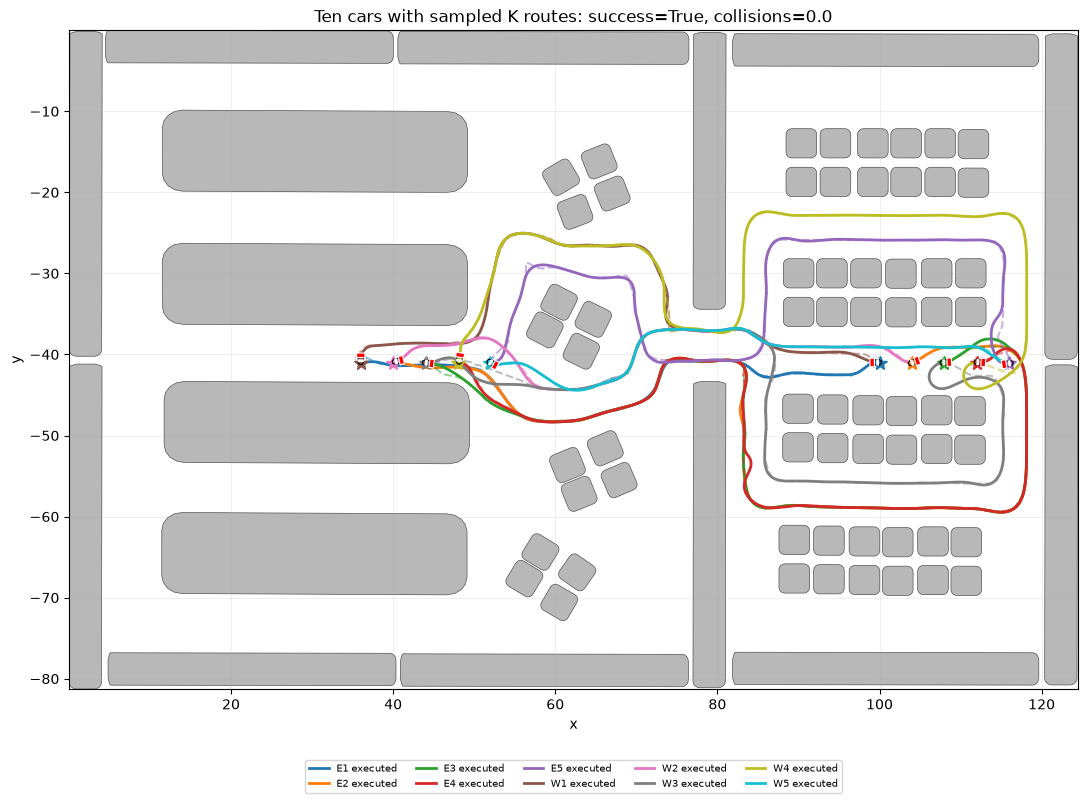

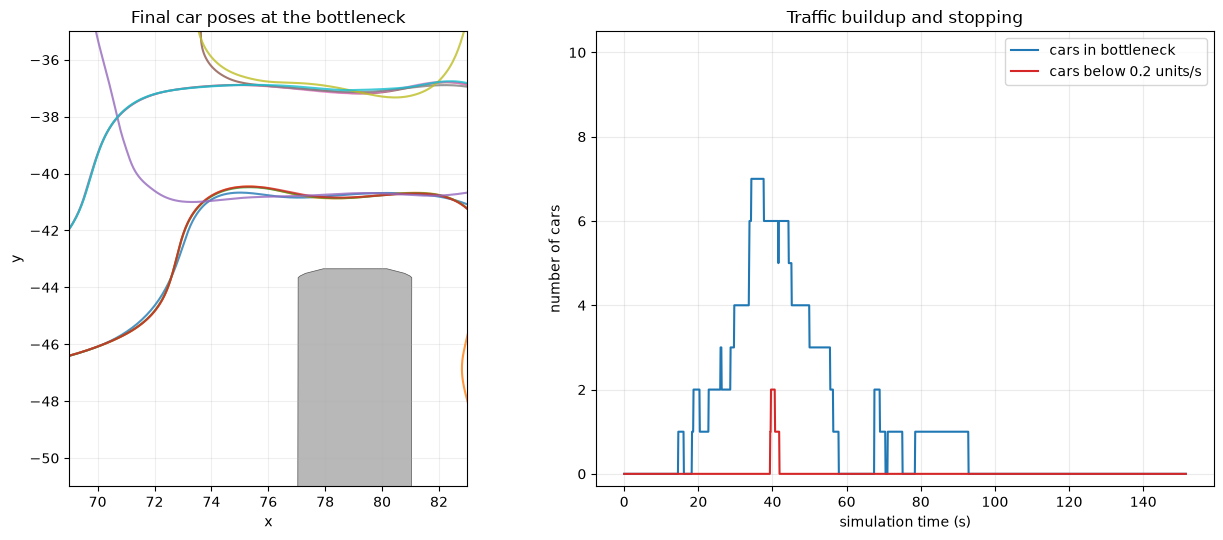

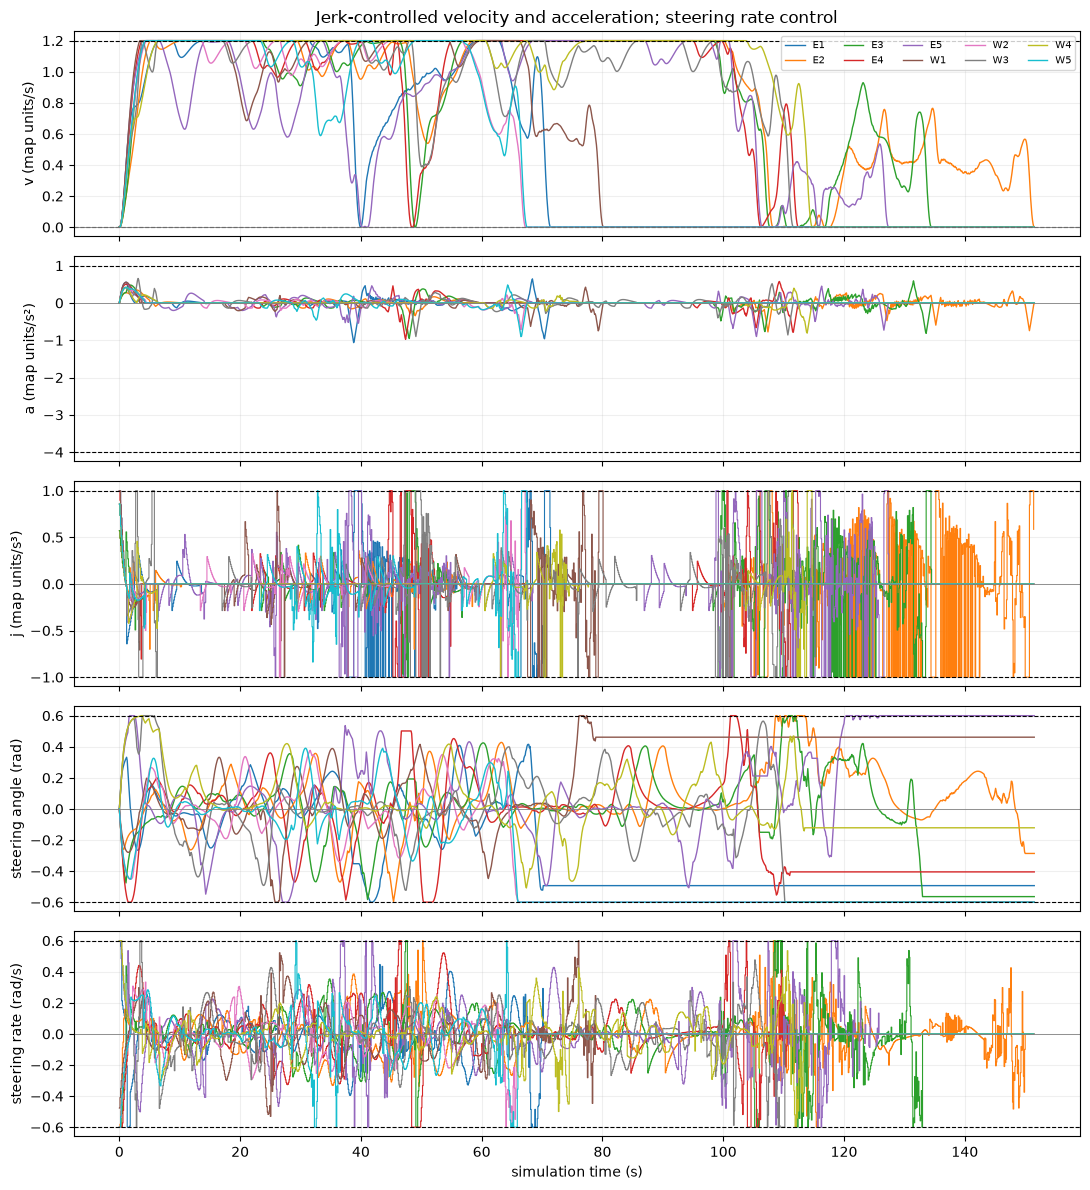

In [6]:
fig, ax = plt.subplots(figsize=(12, 8))
draw_world(ax)
for agent_id, (goal, anchor_path) in enumerate(zip(CUSTOM_GOALS, anchor_paths)):
    color = colors[agent_id]
    anchor = np.asarray(anchor_path)
    ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color, alpha=0.5)
    ax.plot(xy[:, agent_id, 0], xy[:, agent_id, 1], color=color,
            linewidth=2, label=f'{AGENT_NAMES[agent_id]} executed')
    draw_car(ax, states[-1, agent_id], color, safety_circle=True)
    ax.plot(*goal[:2], '*', color=color, markersize=10)
ax.set_title(f'Ten cars with sampled K routes: success={success}, collisions={collisions}')
ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=5)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'executed_routes.png', dpi=160, bbox_inches='tight')
plt.show()

fig, (ax_close, ax_queue) = plt.subplots(1, 2, figsize=(13, 5.5))
draw_world(ax_close)
ax_close.set(xlim=(69, 83), ylim=(-51, -35))
for agent_id in range(AGENTS_NUM):
    color = colors[agent_id]
    ax_close.plot(xy[:, agent_id, 0], xy[:, agent_id, 1], color=color, alpha=0.8)
    draw_car(ax_close, states[-1, agent_id], color, safety_circle=True)
ax_close.set_title('Final car poses at the bottleneck')
times = np.arange(len(states)) * DT
ax_queue.plot(times, choke_counts, label='cars in bottleneck', color='tab:blue')
ax_queue.plot(times, slow_in_choke, label=f'cars below {SLOW_SPEED} units/s', color='tab:red')
ax_queue.set(xlabel='simulation time (s)', ylabel='number of cars',
             ylim=(-0.3, AGENTS_NUM + 0.5), title='Traffic buildup and stopping')
ax_queue.grid(alpha=0.25)
ax_queue.legend()
fig.tight_layout()
plt.show()

# Raw state/control differences: no smoothing or moving averages.
fig, axes = plt.subplots(5, 1, figsize=(11, 12), sharex=True)
state_times = np.arange(len(states)) * DT
control_times = state_times[:-1]
for agent_id, agent_name in enumerate(AGENT_NAMES):
    color = colors[agent_id]
    axes[0].plot(state_times, states[:, agent_id, 3], color=color, label=agent_name, linewidth=1)
    axes[1].plot(state_times, accelerations[:, agent_id], color=color, linewidth=1)
    axes[2].step(control_times, jerks[:, agent_id], where='post', color=color, linewidth=0.8)
    axes[3].plot(state_times, states[:, agent_id, 4], color=color, linewidth=1)
    axes[4].step(control_times, steering_rates[:, agent_id], where='post', color=color, linewidth=0.8)
axes[0].axhline(MAX_SPEED, color='black', linestyle='--', linewidth=0.8)
axes[0].axhline(-REVERSE_MAX_SPEED, color='black', linestyle='--', linewidth=0.8)
axes[0].set(ylabel='v (map units/s)', title='Jerk-controlled velocity and acceleration; steering rate control')
axes[0].legend(fontsize=7, ncol=5)
axes[1].axhline(ACCEL_MAX, color='black', linestyle='--', linewidth=0.8)
axes[1].axhline(-BRAKE_MAX, color='black', linestyle='--', linewidth=0.8)
axes[1].set(ylabel='a (map units/s²)')
axes[2].axhline(JERK_MAX, color='black', linestyle='--', linewidth=0.8)
axes[2].axhline(JERK_MIN, color='black', linestyle='--', linewidth=0.8)
axes[2].set(ylabel='j (map units/s³)')
axes[3].axhline(STEER_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[3].axhline(-STEER_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[3].set(ylabel='steering angle (rad)')
axes[4].axhline(STEER_RATE_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[4].axhline(-STEER_RATE_LIMIT, color='black', linestyle='--', linewidth=0.8)
axes[4].set(ylabel='steering rate (rad/s)', xlabel='simulation time (s)')
for ax in axes:
    ax.axhline(0, color='gray', linewidth=0.6)
    ax.grid(alpha=0.2)
fig.tight_layout()
DYNAMICS_PLOT_PATH = OUTPUT_DIR / 'dynamics.png'
fig.savefig(DYNAMICS_PLOT_PATH, dpi=160)
plt.show()


In [7]:
fig, (ax_map, ax_close) = plt.subplots(
    1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.7, 1]}
)
frame_indices = np.unique(np.linspace(0, len(states) - 1, min(100, len(states))).astype(int))

def animate(frame_number):
    state_index = int(frame_indices[frame_number])
    ax_map.clear()
    ax_close.clear()
    draw_world(ax_map)
    draw_world(ax_close)
    ax_close.set(xlim=(69, 83), ylim=(-51, -35))
    for agent_id, (goal, anchor_path) in enumerate(zip(CUSTOM_GOALS, anchor_paths)):
        color = colors[agent_id]
        anchor = np.asarray(anchor_path)
        for ax in (ax_map, ax_close):
            ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color,
                    alpha=0.35, linewidth=1.1)
            ax.plot(xy[:state_index + 1, agent_id, 0],
                    xy[:state_index + 1, agent_id, 1],
                    color=color, linewidth=1.6)
            draw_car(ax, states[state_index, agent_id], color, safety_circle=True)
            ax.plot(*goal[:2], '*', color=color, markersize=9)
    ax_map.set_title(f'Ten-car ORCA-MPPI: step {state_index}/{len(states) - 1}')
    ax_close.set_title(f'Bottleneck: {choke_counts[state_index]} cars, '
                       f'{slow_in_choke[state_index]} nearly stopped')

animation = FuncAnimation(fig, animate, frames=len(frame_indices), interval=100)
GIF_PATH = OUTPUT_DIR / 'animation.gif'
animation.save(GIF_PATH, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=str(GIF_PATH)))


Animation saved to benchmarks/results/k_routes_warehouse2_car_like_traffic_jam/animation.gif


Raw state and control traces show the smooth forward profile described above. Jerk is bounded to ±1 unit/s³, so acceleration changes by at most 0.1 unit/s² per simulation step. Trajectories are measured directly from the physical model.


In [8]:
# A completed run means every car is physically at rest at its finish.
assert success, 'The selected tasks did not all finish within the simulation budget'
assert collisions == 0, 'The measured run contains collisions'
assert not run_summary['unfinished']
assert run_summary['orca_enabled']
assert np.max(goal_errors) <= exp_params[XY_GOAL_TOLERANCE]
np.testing.assert_allclose(states[-1, :, 3], 0, atol=1e-8)
np.testing.assert_allclose(states[-1, :, 5], 0, atol=1e-8)
assert run_summary['min_swept_static_gap'] >= -1e-7
assert run_summary['min_swept_pair_gap'] >= -1e-7
print(f'Verified {AGENTS_NUM}/{AGENTS_NUM} cars stopped at their finishes, '
      f'zero collisions, ORCA enabled; {steps * DT:.1f} simulated seconds.')


Verified 10/10 cars stopped at their finishes, zero collisions, ORCA enabled; 151.5 simulated seconds.
